In [2]:
!pip install catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import warnings
warnings.filterwarnings('ignore')
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.2
numpy: 2.0.2


In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 20)

In [5]:
df = pd.read_csv("WA_Fn-UseC_-Marketing-Customer-Value-Analysis.csv")
df.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,Suburban,Married,69,32,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,Suburban,Single,94,13,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,Suburban,Married,108,18,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,Suburban,Married,106,18,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,2/3/11,Employed,M,43836,Rural,Single,73,12,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [6]:
# Customer	Клиент (ID клиента)
# State	Штат
# Customer Lifetime Value	Пожизненная ценность клиента (CLV)
# Response	Отклик (на маркетинговое предложение)
# Coverage	Тип страхового покрытия
# Education	Образование
# Effective To Date	Дата вступления в силу
# EmploymentStatus	Статус занятости
# Gender	Пол
# Income	Доход
# Location Code	Код местоположения (тип: город/пригород/сельская местность)
# Marital Status	Семейное положение
# Monthly Premium Auto	Ежемесячная страховая премия за авто
# Months Since Last Claim	Месяцев с последнего страхового случая
# Months Since Policy Inception	Месяцев с момента оформления полиса
# Number of Open Complaints	Количество открытых жалоб
# Number of Policies	Количество полисов
# Policy Type	Тип полиса
# Policy	Конкретный полис (подтип)
# Renew Offer Type	Тип предложения на продление
# Sales Channel	Канал продаж
# Total Claim Amount	Общая сумма страховых выплат
# Vehicle Class	Класс автомобиля
# Vehicle Size	Размер автомобиля

In [7]:
df.shape

(9134, 24)

In [8]:
df.describe()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,8004.940475,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794
std,6870.967608,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092
min,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007
25%,3994.251794,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244
50%,5780.182197,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434
75%,8962.167041,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839
max,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678


In [9]:
df.isnull().sum()

,0
Customer,0
State,0
Customer Lifetime Value,0
Response,0
Coverage,0
Education,0
Effective To Date,0
EmploymentStatus,0
Gender,0
Income,0


In [10]:
print(list(df.columns))

['Customer', 'State', 'Customer Lifetime Value', 'Response', 'Coverage', 'Education', 'Effective To Date', 'EmploymentStatus', 'Gender', 'Income', 'Location Code', 'Marital Status', 'Monthly Premium Auto', 'Months Since Last Claim', 'Months Since Policy Inception', 'Number of Open Complaints', 'Number of Policies', 'Policy Type', 'Policy', 'Renew Offer Type', 'Sales Channel', 'Total Claim Amount', 'Vehicle Class', 'Vehicle Size']


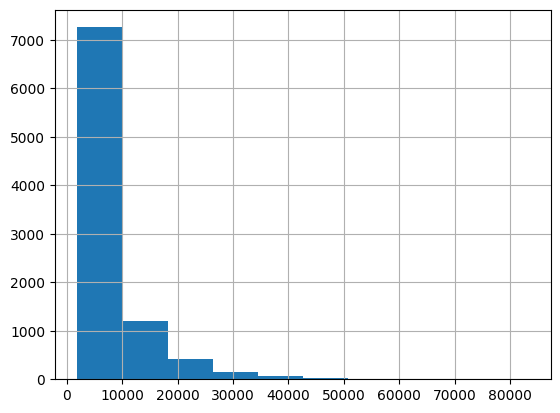

In [11]:
df["Customer Lifetime Value"].hist();

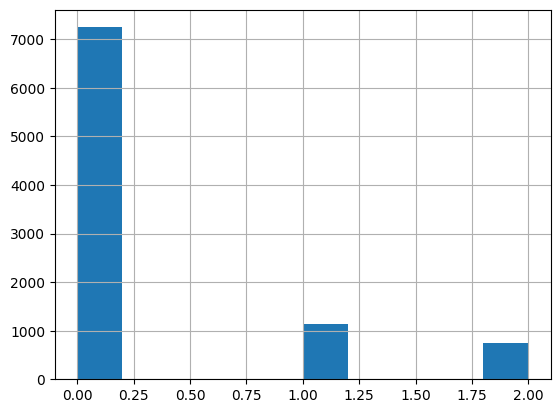

In [12]:
# Сбалансирую классы

def customer_value_score(x):
    if x < 10000:
        return 0
    elif x >= 10000 and x <= 17000:
        return 1
    else:
        return 2

df["Customer Lifetime Value"] = df["Customer Lifetime Value"].apply(customer_value_score)

df["Customer Lifetime Value"].hist();

In [13]:
df["Customer Lifetime Value"].unique()

array([0, 1, 2])

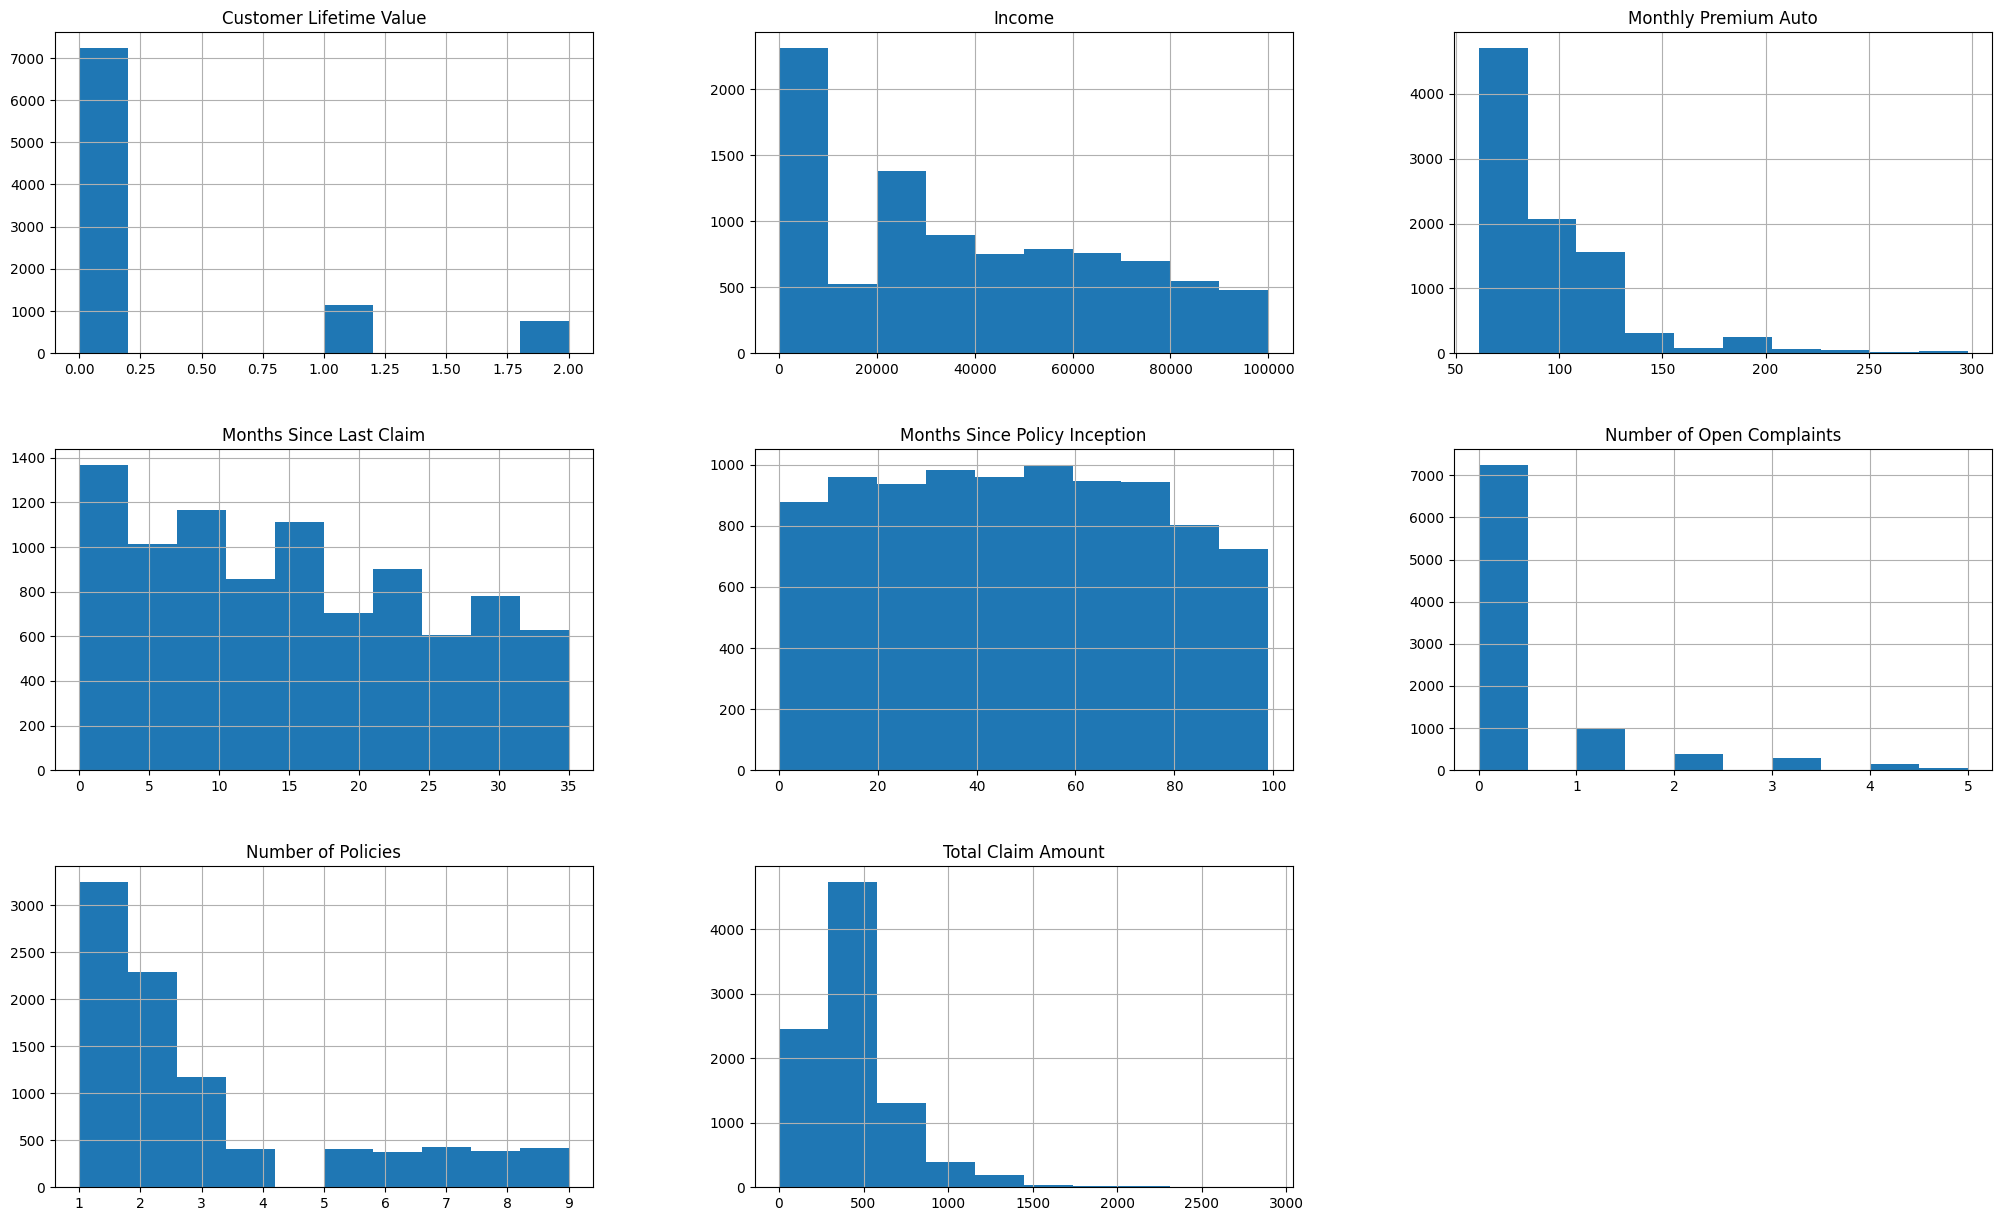

In [14]:
df.hist(figsize=(25, 15))

plt.show()

<Axes: >

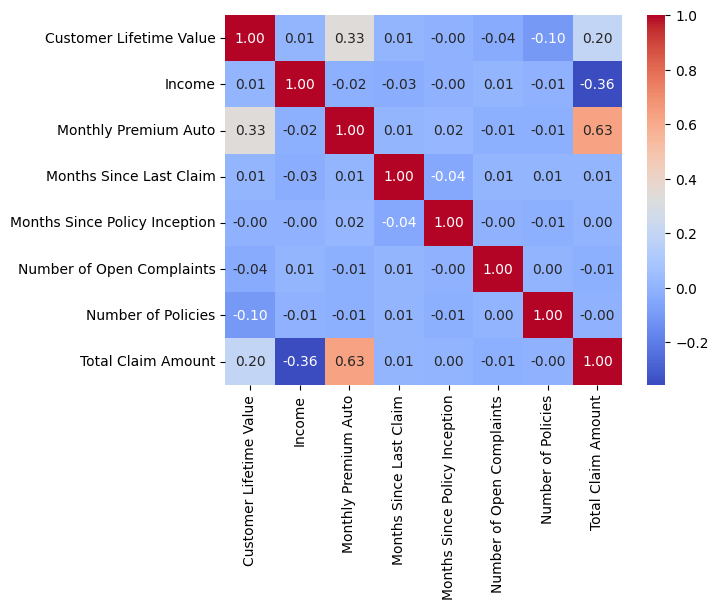

In [15]:
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

Наиболее коррелирующие колонки - это Total Claim Amount	(Общая сумма страховых выплат) и Monthly Premium Auto	(Ежемесячная страховая премия за авто)

In [16]:
print(df.columns.tolist())

['Customer', 'State', 'Customer Lifetime Value', 'Response', 'Coverage', 'Education', 'Effective To Date', 'EmploymentStatus', 'Gender', 'Income', 'Location Code', 'Marital Status', 'Monthly Premium Auto', 'Months Since Last Claim', 'Months Since Policy Inception', 'Number of Open Complaints', 'Number of Policies', 'Policy Type', 'Policy', 'Renew Offer Type', 'Sales Channel', 'Total Claim Amount', 'Vehicle Class', 'Vehicle Size']


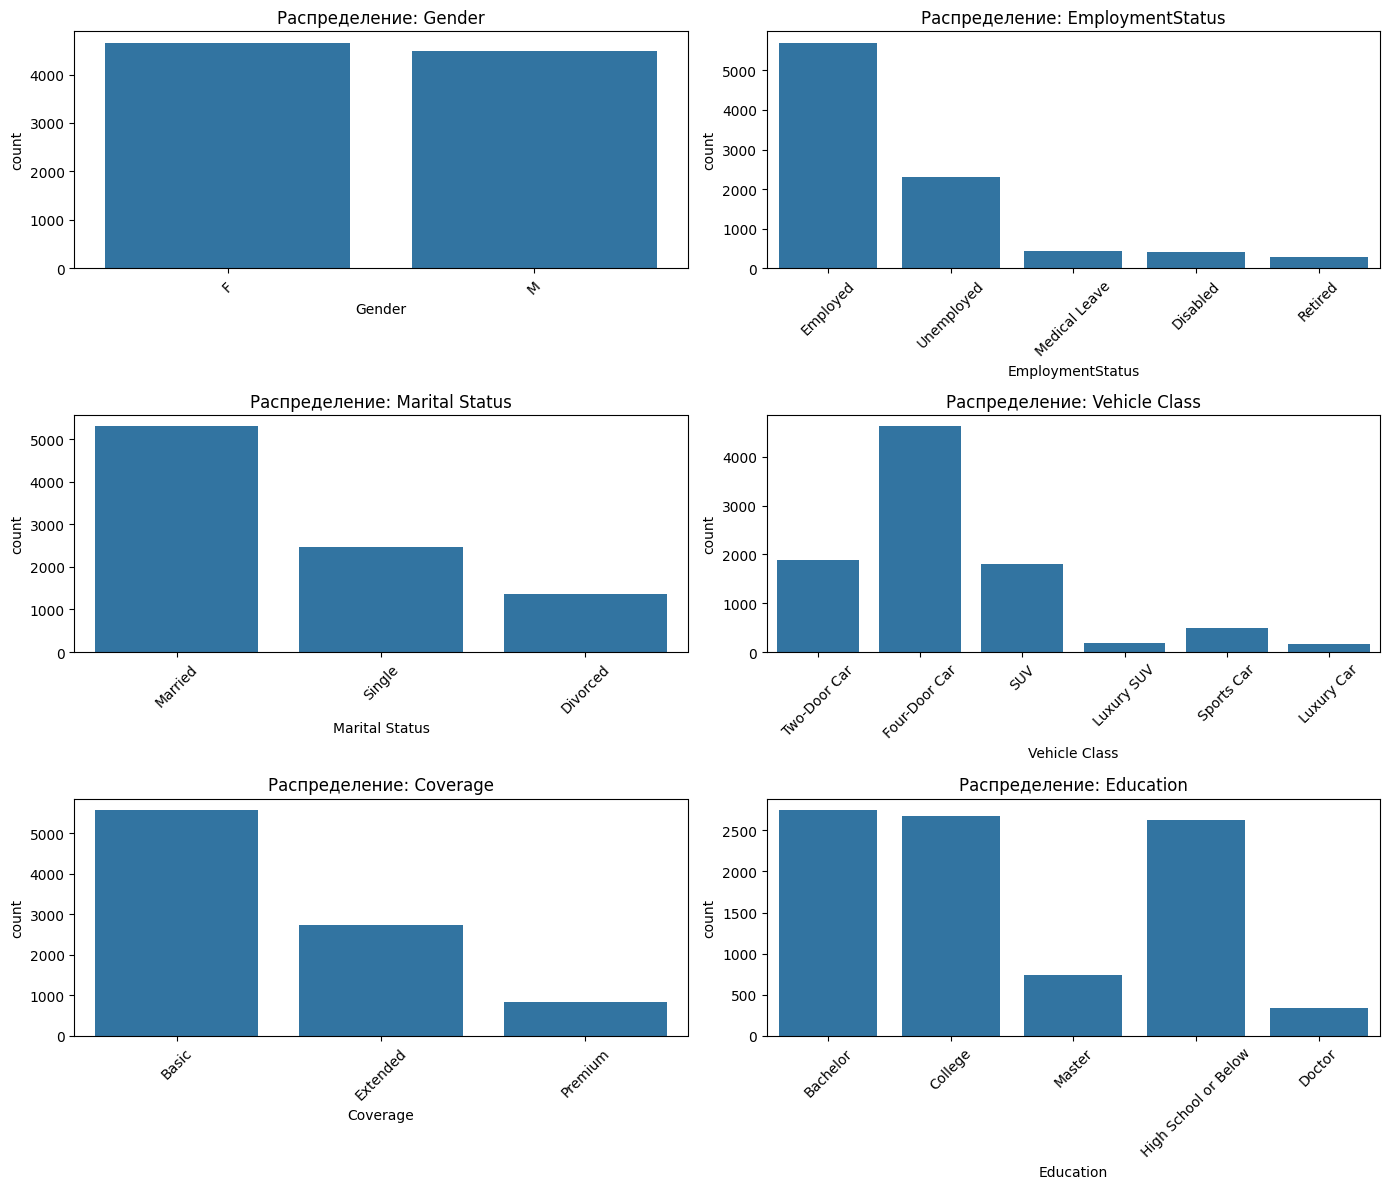

In [17]:
# анализ категориальных признаков
categorical_cols_eda = ['Gender', 'EmploymentStatus', 'Marital Status',
                         'Vehicle Class', 'Coverage', 'Education']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols_eda):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Распределение: {col}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

На графиках видно, что в большинстве категорий данные распределены неравномерно. Пример:
1. женатых клиентов больше, чем
разведённых,
2. Bachelor самое большое значение в образовании,
3. Разные классы автомобилей, типы страховок (покрытие) и обрразование.

In [18]:
#связь категорий с целевой переменной
for col in categorical_cols_eda:
    print(f"\n{col}:")
    print(df.groupby(col)['Customer Lifetime Value'].mean().sort_values(ascending=False))


Gender:
Gender
F    0.301417
M    0.276586
Name: Customer Lifetime Value, dtype: float64

EmploymentStatus:
EmploymentStatus
Retired          0.326241
Employed         0.297122
Medical Leave    0.291667
Disabled         0.276543
Unemployed       0.267156
Name: Customer Lifetime Value, dtype: float64

Marital Status:
Marital Status
Divorced    0.322133
Married     0.285202
Single      0.279692
Name: Customer Lifetime Value, dtype: float64

Vehicle Class:
Vehicle Class
Luxury SUV       1.016304
Luxury Car       1.000000
Sports Car       0.458678
SUV              0.447105
Two-Door Car     0.204136
Four-Door Car    0.190868
Name: Customer Lifetime Value, dtype: float64

Coverage:
Coverage
Premium     0.504854
Extended    0.354121
Basic       0.225395
Name: Customer Lifetime Value, dtype: float64

Education:
Education
Master                  0.309042
High School or Below    0.306636
College                 0.281238
Bachelor                0.278020
Doctor                  0.266082
Name: Cus

In [19]:
# Сколько строк каждой категории попадает в каждый класс
for col in categorical_cols_eda:
    print(f"\n{col}:")
    print(pd.crosstab(df[col], df['Customer Lifetime Value'], normalize='index').round(2))


Gender:
Customer Lifetime Value     0     1     2
Gender                                   
F                        0.79  0.12  0.09
M                        0.80  0.13  0.08

EmploymentStatus:
Customer Lifetime Value     0     1     2
EmploymentStatus                         
Disabled                 0.80  0.13  0.07
Employed                 0.79  0.13  0.08
Medical Leave            0.79  0.13  0.08
Retired                  0.74  0.19  0.07
Unemployed               0.81  0.10  0.08

Marital Status:
Customer Lifetime Value     0     1     2
Marital Status                           
Divorced                 0.77  0.14  0.09
Married                  0.80  0.12  0.08
Single                   0.80  0.12  0.08

Vehicle Class:
Customer Lifetime Value     0     1     2
Vehicle Class                            
Four-Door Car            0.87  0.07  0.06
Luxury Car               0.32  0.36  0.32
Luxury SUV               0.34  0.30  0.36
SUV                      0.66  0.23  0.11
Sports Car     

1. Разбивка по полу, семейному положению, образованию не влияют на  модель, потому что среднее значение незначительно.

2. Чем выше уровень страховки (Premium
против Basic), тем выше ценность клиента

## Preprocessing & Feature Engineering

In [20]:
target = ['Customer Lifetime Value']
data_cleaned = df.copy()

In [21]:
# Добавляю новый признак (извлекаю месц) и удаляю исходную колонку
data_cleaned['Effective To Date'] = pd.to_datetime(data_cleaned['Effective To Date'])
data_cleaned['Effective Month'] = data_cleaned['Effective To Date'].dt.month
data_cleaned = data_cleaned.drop(columns=['Effective To Date'])

In [22]:
numerical_features = ['Income', 'Monthly Premium Auto', 'Months Since Last Claim',
                       'Months Since Policy Inception', 'Number of Open Complaints',
                       'Number of Policies', 'Total Claim Amount', 'Effective Month']

categorical_features = [
    col for col in data_cleaned.columns if col not in numerical_features + target + ['Customer']
]

all_features = categorical_features + numerical_features

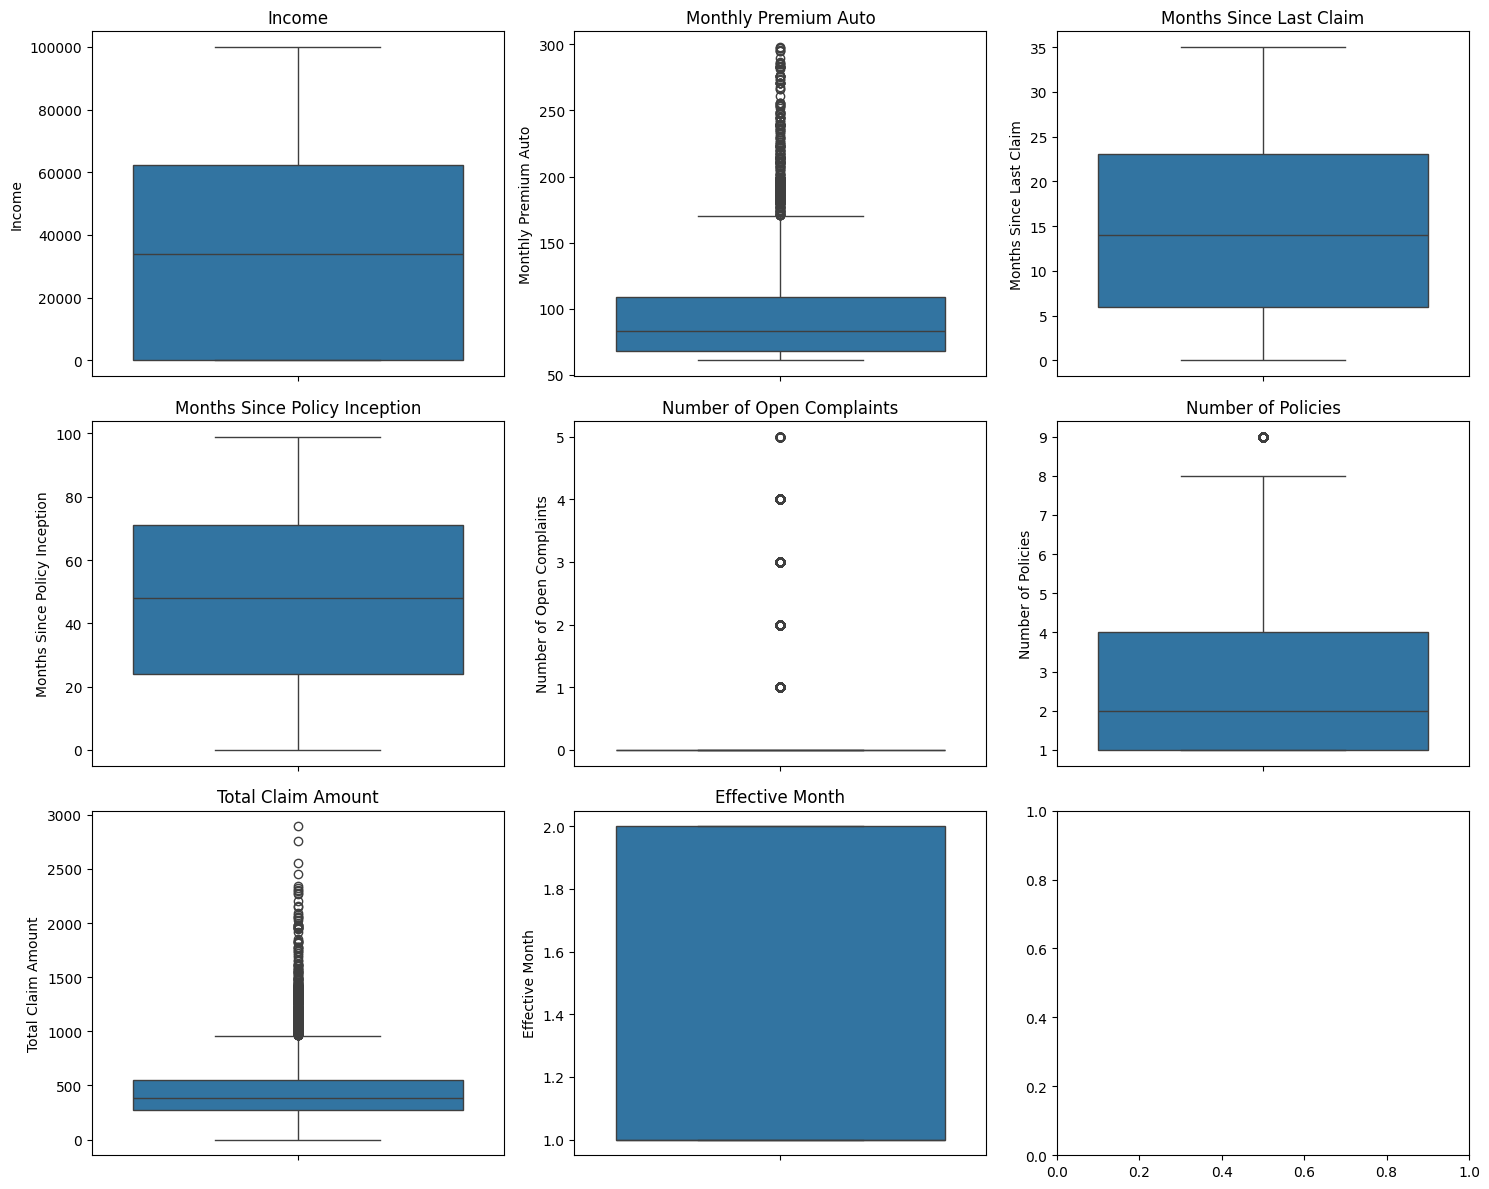

In [23]:
# Выбросы
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(data=data_cleaned, y=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

Больше всего выбросов у Monthly Premium Auto и Total Claim Amount.  У некоторых клиентов сумма выплат заметно выше основной массы. Не стала убирать эти строки, так как буду использовать бустинги + вероятно, это дорогая машина или большая страховая выплата.

In [24]:
data_train, data_test = train_test_split(data_cleaned, test_size=0.2, stratify=data_cleaned[target], random_state = 42)

print(data_train.shape, data_test.shape)

(7307, 24) (1827, 24)


In [25]:
data_test.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Effective Month
6270,JX60415,Arizona,0,Yes,Extended,Master,Employed,F,58557,Rural,Married,88,4,83,0,1,Personal Auto,Personal L2,Offer1,Branch,55.510526,Four-Door Car,Large,1
8454,BQ32117,California,1,Yes,Basic,Doctor,Employed,M,40870,Suburban,Married,105,3,56,0,2,Personal Auto,Personal L1,Offer1,Agent,504.000000,SUV,Large,1
4230,VE51810,Arizona,0,No,Basic,Bachelor,Employed,M,42795,Suburban,Married,73,2,38,0,4,Personal Auto,Personal L1,Offer3,Branch,350.400000,Four-Door Car,Large,1
4207,WF44706,Oregon,0,Yes,Extended,High School or B...,Employed,M,26876,Suburban,Single,76,17,72,0,8,Personal Auto,Personal L3,Offer1,Agent,364.800000,Four-Door Car,Medsize,1
3303,BZ85280,Oregon,0,No,Basic,College,Medical Leave,M,10334,Urban,Married,64,5,80,0,2,Personal Auto,Personal L1,Offer3,Agent,296.962938,Four-Door Car,Medsize,2


In [26]:
for col in categorical_features:
    train_categories = set(data_train[col].unique())
    test_categories = set(data_test[col].unique())

    missing_in_train = test_categories - train_categories

    if missing_in_train:
        print(f"{col}: в test есть категории, которых нет в train -> {missing_in_train}")
    else:
        print(f"{col}: все категории test есть в train")

State: все категории test есть в train
Response: все категории test есть в train
Coverage: все категории test есть в train
Education: все категории test есть в train
EmploymentStatus: все категории test есть в train
Gender: все категории test есть в train
Location Code: все категории test есть в train
Marital Status: все категории test есть в train
Policy Type: все категории test есть в train
Policy: все категории test есть в train
Renew Offer Type: все категории test есть в train
Sales Channel: все категории test есть в train
Vehicle Class: все категории test есть в train
Vehicle Size: все категории test есть в train


In [27]:
encoders = {}

for col in categorical_features:
    le = LabelEncoder()
    le.fit(data_train[col])

    data_train[col] = le.transform(data_train[col])
    data_test[col] = le.transform(data_test[col])

    encoders[col] = le

In [28]:
data_train[categorical_features].head()
data_train.dtypes

,0
Customer,object
State,int64
Customer Lifetime Value,int64
Response,int64
Coverage,int64
Education,int64
EmploymentStatus,int64
Gender,int64
Income,int64
Location Code,int64


In [29]:
data_train.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Effective Month
8893,XE72624,1,0,0,0,3,1,0,34653,1,1,64,18,72,0,1,0,0,3,1,307.200000,0,2,2
5646,XZ45224,3,0,0,0,1,1,0,38961,1,0,62,5,19,0,1,0,2,0,0,297.600000,5,1,2
5498,YP79029,1,1,0,0,0,1,1,34179,1,1,107,15,26,0,2,0,2,1,3,770.400000,4,1,2
6165,QO26846,3,0,0,1,4,2,0,16891,1,2,88,15,54,0,1,1,5,3,2,633.600000,0,1,2
2776,XF96605,1,0,0,0,1,1,1,94362,2,0,74,21,96,0,1,1,4,0,0,195.405949,5,0,1


In [30]:
X_train = data_train[all_features]
y_train = data_train[target[0]]

X_test = data_test[all_features]
y_test = data_test[target[0]]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(7307, 22) (1827, 22)
(7307,) (1827,)


In [31]:
X_train.dtypes.unique()
X_train.isnull().sum().sum()

np.int64(0)

# Обучение

In [32]:
models = {
    'sklearn GB': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(),
    'CatBoost': CatBoostClassifier(logging_level='Silent'),
    'LightGBM': LGBMClassifier(verbose=-1),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    proba = model.predict_proba(X_test)
    preds = model.predict(X_test)

    auc = roc_auc_score(y_test, proba, multi_class='ovr')
    f1 = f1_score(y_test, preds, average='macro')

    results[name] = {'roc_auc': auc, 'f1_macro': f1}
    print(f"{name}: ROC-AUC={auc:.4f}, F1-macro={f1:.4f}")

sklearn GB: ROC-AUC=0.9701, F1-macro=0.7299
XGBoost: ROC-AUC=0.9688, F1-macro=0.7197
CatBoost: ROC-AUC=0.9700, F1-macro=0.7358
LightGBM: ROC-AUC=0.9712, F1-macro=0.7393


In [33]:
#Сделала не через GridSearchCV из-за объема
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'sklearn GB': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [2, 3, 4, 5],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [2, 3, 4, 5, 6],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
    },
    'CatBoost': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [4, 6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
    },
    'LightGBM': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [3, 5, 7, -1],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
    },
}

base_models = {
    'sklearn GB': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(),
    'CatBoost': CatBoostClassifier(logging_level='Silent'),
    'LightGBM': LGBMClassifier(verbose=-1),
}

best_models = {}
tuned_results = {}

for name, model in base_models.items():

    search = RandomizedSearchCV(
        model,
        param_distributions=param_distributions[name],
        n_iter=15,
        scoring='f1_macro',
        cv=3,
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    print(f"  Лучшие параметры: {search.best_params_}")

  Лучшие параметры: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.2}
  Лучшие параметры: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
  Лучшие параметры: {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.2}
  Лучшие параметры: {'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.01}


In [34]:
for name, model in best_models.items():
    proba = model.predict_proba(X_test)
    preds = model.predict(X_test)

    auc = roc_auc_score(y_test, proba, multi_class='ovr')
    f1 = f1_score(y_test, preds, average='macro')

    tuned_results[name] = {'roc_auc': auc, 'f1_macro': f1}
    print(f"{name}: ROC-AUC={auc:.4f}, F1-macro={f1:.4f}")

sklearn GB: ROC-AUC=0.9663, F1-macro=0.7247
XGBoost: ROC-AUC=0.9719, F1-macro=0.7445
CatBoost: ROC-AUC=0.9712, F1-macro=0.7428
LightGBM: ROC-AUC=0.9722, F1-macro=0.7451


In [39]:
comparison = pd.DataFrame({
    'baseline_f1': {k: v['f1_macro'] for k, v in results.items()},
    'new_f1': {k: v['f1_macro'] for k, v in tuned_results.items()},
    'baseline_auc': {k: v['roc_auc'] for k, v in results.items()},
    'new_auc': {k: v['roc_auc'] for k, v in tuned_results.items()},
})
comparison

,baseline_f1,new_f1,baseline_auc,new_auc
sklearn GB,0.729884,0.724748,0.970117,0.966271
XGBoost,0.719683,0.744509,0.968837,0.971859
CatBoost,0.735803,0.742809,0.970042,0.971160
LightGBM,0.739298,0.745120,0.971224,0.972181


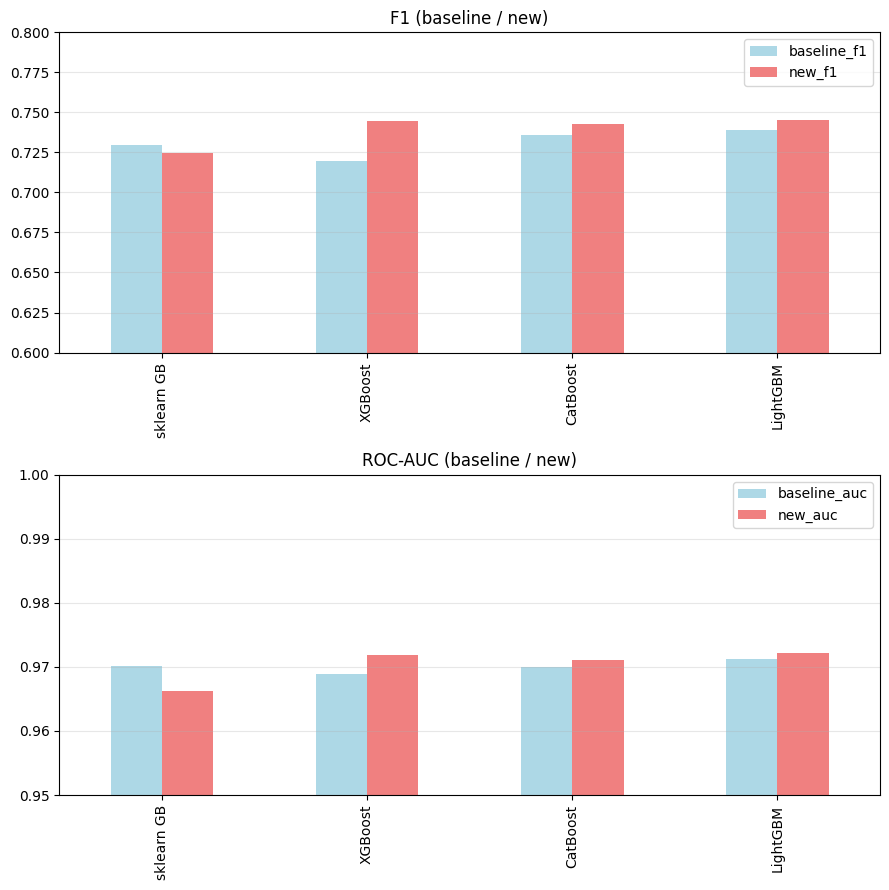

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(9, 9))

comparison[['baseline_f1', 'new_f1']].plot(kind='bar', ax=axes[0], color=['lightblue', 'lightcoral'])
axes[0].set_title('F1 (baseline / new)')
axes[0].set_ylim(0.6, 0.8)
axes[0].grid(axis='y', alpha=0.3)

comparison[['baseline_auc', 'new_auc']].plot(kind='bar', ax=axes[1], color=['lightblue', 'lightcoral'])
axes[1].set_title('ROC-AUC (baseline / new)')
axes[1].set_ylim(0.95, 1.0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Выводы

Лучшие расчеты на LightGBM, где F1 0.739 и ROC-AUC 0.971. CatBoost и sklearn GB показали почти одинаковые результаты, а XGBoost оказался самым слабым.

После подбора гиперпараметров через RandomizedSearchCV LightGBM снова показал лучшие результаты, F1 увеличился до 0.745, при этом XGBoost и CatBoost приблизительно с такими же результатами, sklearn GB стал незначительно меньше после
подбора гиперпараметров (F1 изменился с 0.730 до 0.725)

LightGBM для данной выгрузки оказался лучшим до и после настройки.

По графикам сравнения (baseline и new) видно, что улучшения от гиперпараметров низкие.  У большинства моделей прирост F1 незначителен, а ROC-AUC у всех моделей был близок к 0.97 даже до настройки.